# Chapitre 11 - Exercices 11.5 à 11.7

Ces trois exercices sont des travaux pratiques : programmer un réseau de neurones avec
rétropropagation et weight decay et l'étudier sur une simulation (11.5), programmer la
projection pursuit regression et la comparer au réseau (11.6), puis comparer réseau et modèle
additif sur les données *spam* (11.7).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch11_reseaux import MLP, PPR, SmoothingSpline, backprop, one_hot, sigmoid

## Exercice 11.5 : Réseau à dix unités : époques, weight decay et nombre d'unités

**Énoncé (reformulé).**

(a) Écrire un programme qui ajuste un réseau à une couche cachée (dix unités) par
rétropropagation avec weight decay.

(b) L'appliquer à 100 observations du modèle

$$Y = \sigma(a_1^TX) + (a_2^TX)^2 + 0{,}30\cdot Z,$$

où $\sigma$ est la sigmoïde, $Z$ une gaussienne centrée réduite, $X = (X_1, X_2)$ à composantes
gaussiennes centrées réduites indépendantes, $a_1 = (3, 3)$ et $a_2 = (3, -3)$. Tirer un
échantillon de test de taille 1000 et tracer les erreurs d'apprentissage et de test en
fonction du nombre d'époques, pour plusieurs valeurs du paramètre de weight decay. Discuter le
sur-ajustement dans chaque cas.

(c) Faire varier le nombre d'unités cachées de 1 à 10 et déterminer le nombre minimal
nécessaire pour bien résoudre ce problème.

### (a) Le programme

Le programme est la classe `MLP` du module `esl/ch11_reseaux.py`, dont le cœur est la fonction
`backprop` (cours 2) :

* passe avant : $z_{mi} = \sigma(\alpha_{0m} + \alpha_m^Tx_i)$, $f(x_i) = \beta_0 + \beta^Tz_i$ ;
* passe arrière : $\delta_i = -2(y_i - f(x_i))$, $s_{mi} = z_{mi}(1 - z_{mi})\,\beta_m\delta_i$ ;
* gradient : $\partial R/\partial\beta_m = \sum_i\delta_i z_{mi} + 2\lambda\beta_m$,
  $\partial R/\partial\alpha_{m\ell} = \sum_i s_{mi}x_{i\ell} + 2\lambda\alpha_{m\ell}$ (constantes non pénalisées).

Pour l'entraînement par époques, nous écrivons ici explicitement la boucle de **descente de
gradient par lots avec inertie** (*momentum*) : on garde une « vitesse » $v$ et l'on itère

$$v \leftarrow \mu\, v - \gamma\,\frac{1}{N}\nabla\big(R + \lambda J\big)(\theta), \qquad \theta \leftarrow \theta + v,$$

avec $\mu \in [0, 1)$. Pour $\mu = 0$ c'est la descente (11.13) ; $\mu > 0$ accumule les directions
de descente persistantes et accélère beaucoup la traversée des plateaux.

In [2]:
from esl.ch11_reseaux import init_params, pack, unpack

def entrainer(X, y, M=10, lam=0.0, lr=0.5, mu=0.9, n_epochs=5000, seed=0,
              suivi=None, tous_les=50):
    """Descente de gradient par lots avec inertie ; suivi(params) appelé toutes les `tous_les` époques."""
    N, p = X.shape
    Y = y[:, None]
    theta = pack(init_params(p, M, 1, np.random.RandomState(seed), scale=0.5))
    v = np.zeros_like(theta)
    for epoch in range(1, n_epochs + 1):
        _, g = backprop(unpack(theta, p, M, 1), X, Y, weight_decay=lam)
        v = mu * v - lr * pack(g) / N
        theta = theta + v
        if suivi is not None and epoch % tous_les == 0:
            suivi(epoch, unpack(theta, p, M, 1))
    return unpack(theta, p, M, 1)

### (b) Les données

Calculons d'abord l'ordre de grandeur du signal. Comme $a_2^TX = 3X_1 - 3X_2 \sim \mathcal N(0, 18)$,
$(a_2^TX)^2 = 18\,\chi^2_1$ a pour variance $18^2\times 2 = 648$, alors que la partie sigmoïde varie
dans $[0,1]$ et que le bruit a pour variance $0{,}09$ : le **rapport signal sur bruit est énorme**
(de l'ordre de 6000). L'erreur de Bayes est $\sigma^2 = 0{,}09$.

Pour l'ajustement, on **standardise** la réponse (centrage et division par son écart-type
$\approx 25$), on ajuste le réseau, puis on revient à l'échelle d'origine pour mesurer les erreurs.
Les entrées sont déjà centrées réduites. Le paramètre $\lambda$ s'entend donc pour la réponse
standardisée.

In [3]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])

def f_vraie(X):
    return sigmoid(X @ a1) + (X @ a2) ** 2

rng = np.random.RandomState(0)
X = rng.randn(100, 2)
y = f_vraie(X) + 0.3 * rng.randn(100)
X_test = rng.randn(1000, 2)
y_test = f_vraie(X_test) + 0.3 * rng.randn(1000)
bayes = 0.3 ** 2
mu_y, sd_y = y.mean(), y.std()
print("Var f(X) (test) = %.0f ; variance du bruit = %.2f ; écart-type de y = %.1f"
      % (np.var(f_vraie(X_test)), bayes, sd_y))

Var f(X) (test) = 600 ; variance du bruit = 0.09 ; écart-type de y = 25.6


On entraîne 20 000 époques pour quatre valeurs de $\lambda$, en enregistrant les erreurs
quadratiques moyennes d'apprentissage et de test (divisées par l'erreur de Bayes) toutes les
50 époques.

In [4]:
def courbes_epoques(X, y, X_test, y_test, bayes, lams, n_epochs=20000):
    mu_y, sd_y = y.mean(), y.std()
    out = {}
    for lam in lams:
        app, test, ep = [], [], []

        def suivi(epoch, params):
            from esl.ch11_reseaux import forward
            ep.append(epoch)
            app.append(np.mean((y - mu_y - sd_y * forward(params, X)["F"][:, 0]) ** 2) / bayes)
            test.append(np.mean((y_test - mu_y - sd_y * forward(params, X_test)["F"][:, 0]) ** 2) / bayes)

        entrainer(X, (y - mu_y) / sd_y, lam=lam, n_epochs=n_epochs, suivi=suivi)
        out[lam] = (np.array(ep), np.array(app), np.array(test))
    return out

lams = [0.0, 1e-4, 1e-3, 1e-2]
res_b = courbes_epoques(X, y, X_test, y_test, bayes, lams)

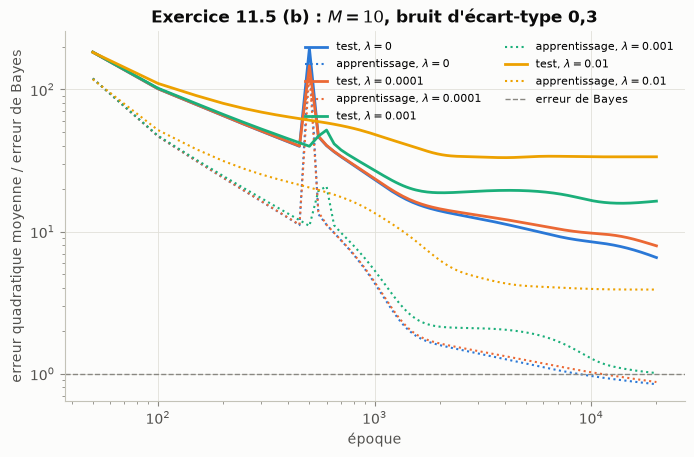

In [5]:
def tracer_courbes(res, titre):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for c, (lam, (ep, app, test)) in zip(COLORS, res.items()):
        ax.plot(ep, test, color=c, label=r"test, $\lambda = %g$" % lam)
        ax.plot(ep, app, ":", color=c, lw=1.5, label=r"apprentissage, $\lambda = %g$" % lam)
    ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("époque")
    ax.set_ylabel("erreur quadratique moyenne / erreur de Bayes")
    ax.set_title(titre)
    ax.legend(ncol=2, fontsize=8)
    plt.show()

tracer_courbes(res_b, r"Exercice 11.5 (b) : $M = 10$, bruit d'écart-type 0,3")

In [6]:
for lam, (ep, app, test) in res_b.items():
    k = int(np.argmin(test))
    print("lambda = %-6g : erreur finale app. = %7.2f, test = %7.2f ; test minimal = %6.2f à l'époque %d"
          % (lam, app[-1], test[-1], test[k], ep[k]))

lambda = 0      : erreur finale app. =    0.84, test =    6.56 ; test minimal =   6.56 à l'époque 20000
lambda = 0.0001 : erreur finale app. =    0.87, test =    7.94 ; test minimal =   7.94 à l'époque 20000
lambda = 0.001  : erreur finale app. =    1.01, test =   16.37 ; test minimal =  15.82 à l'époque 13800
lambda = 0.01   : erreur finale app. =    3.91, test =   33.58 ; test minimal =  33.13 à l'époque 4000


**Discussion.**

* Sans weight decay ($\lambda = 0$), l'erreur de test **décroît pendant tout l'entraînement** : il
  n'y a pratiquement pas de sur-ajustement. Le bruit est minuscule devant le signal : coller aux
  données, c'est coller à la vraie fonction. L'écart entre erreur d'apprentissage et de test
  vient surtout de l'**extrapolation** : la parabole $(a_2^TX)^2$ prend des valeurs très grandes
  dans les queues de la loi de $X$, peu représentées parmi 100 points.
* Le weight decay **dégrade** ici la solution : il empêche les poids d'atteindre les grandes
  valeurs nécessaires pour reproduire la parabole, ce qui introduit un **biais** ; plus $\lambda$
  est grand, plus les courbes se stabilisent tôt, à un niveau élevé. Il n'y a rien à gagner à
  régulariser quand la variance est négligeable.
* Le pic passager vers l'époque 500 n'est pas du sur-ajustement : c'est une instabilité de la
  descente avec inertie (la « vitesse » accumulée fait brièvement dépasser le fond d'une vallée).

Pour voir le sur-ajustement et l'intérêt du weight decay, reprenons la même expérience avec un
bruit **beaucoup plus fort**, d'écart-type 12 (rapport signal sur bruit d'environ 4, comme à la
section 11.6).

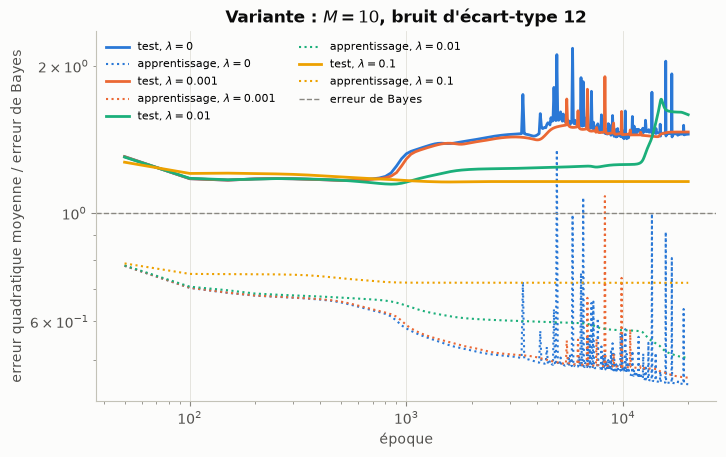

In [7]:
rng = np.random.RandomState(1)
sd_bruit = 12.0
y_b = f_vraie(X) + sd_bruit * rng.randn(100)
y_test_b = f_vraie(X_test) + sd_bruit * rng.randn(1000)
res_bruit = courbes_epoques(X, y_b, X_test, y_test_b, sd_bruit ** 2, [0.0, 1e-3, 1e-2, 1e-1])
tracer_courbes(res_bruit, r"Variante : $M = 10$, bruit d'écart-type 12")

In [8]:
for lam, (ep, app, test) in res_bruit.items():
    k = int(np.argmin(test))
    print("lambda = %-6g : erreur finale app. = %5.2f, test = %5.2f ; test minimal = %5.2f à l'époque %d"
          % (lam, app[-1], test[-1], test[k], ep[k]))

lambda = 0      : erreur finale app. =  0.45, test =  1.45 ; test minimal =  1.17 à l'époque 500
lambda = 0.001  : erreur finale app. =  0.46, test =  1.46 ; test minimal =  1.17 à l'époque 500
lambda = 0.01   : erreur finale app. =  0.51, test =  1.59 ; test minimal =  1.15 à l'époque 850
lambda = 0.1    : erreur finale app. =  0.72, test =  1.16 ; test minimal =  1.16 à l'époque 1550


Avec un bruit fort, le comportement classique apparaît : sans pénalité, l'erreur
d'**apprentissage** passe sous l'erreur de Bayes (le réseau apprend le bruit) et l'erreur de
**test** passe par un minimum puis remonte - l'arrêt précoce serait bénéfique. Un weight decay
modéré stabilise l'erreur de test près de son minimum quel que soit le nombre d'époques : la
pénalité joue le rôle de l'arrêt précoce, sans avoir à choisir le moment d'arrêter.

### (c) Nombre d'unités cachées

Revenons au modèle de l'énoncé (bruit 0,3). Pour $M = 1, \dots, 10$ et 10 poids initiaux, on
ajuste le réseau jusqu'à convergence par L-BFGS (plus rapide que la descente de gradient), sans
weight decay puisque la question (b) a montré qu'il était inutile ici.

In [9]:
Ms = list(range(1, 11))
res_c = []
for M in Ms:
    errs = []
    for seed in range(10):
        net = MLP(n_hidden=M, weight_decay=0.0, random_state=seed)
        net.fit(X, (y - mu_y) / sd_y, max_iter=3000)
        errs.append(np.mean((y_test - mu_y - sd_y * net.predict(X_test)[:, 0]) ** 2) / bayes)
    res_c.append(errs)
    print("M = %2d : erreur de test relative médiane = %8.2f, minimale = %7.2f"
          % (M, np.median(errs), np.min(errs)))

M =  1 : erreur de test relative médiane =  3771.43, minimale = 3771.42
M =  2 : erreur de test relative médiane =     1.36, minimale =    1.31


M =  3 : erreur de test relative médiane =     1.51, minimale =    1.31


M =  4 : erreur de test relative médiane =     1.42, minimale =    1.06


M =  5 : erreur de test relative médiane =     1.85, minimale =    1.29


M =  6 : erreur de test relative médiane =     1.97, minimale =    1.56


M =  7 : erreur de test relative médiane =     2.25, minimale =    1.57


M =  8 : erreur de test relative médiane =     2.44, minimale =    1.81


M =  9 : erreur de test relative médiane =     2.51, minimale =    1.71


M = 10 : erreur de test relative médiane =     2.55, minimale =    1.67


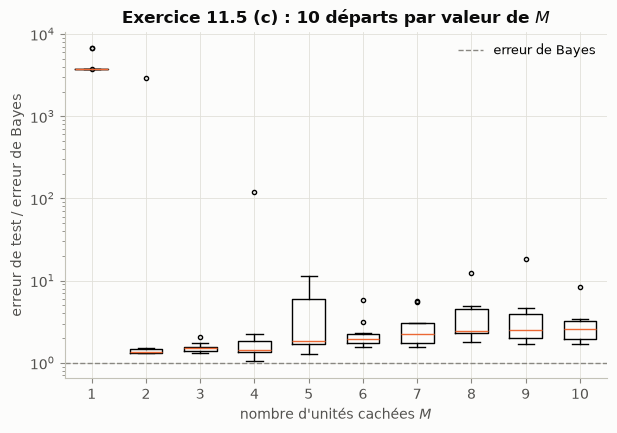

In [10]:
fig, ax = plt.subplots()
ax.boxplot(res_c, positions=Ms, widths=0.6, medianprops=dict(color=ORANGE),
           flierprops=dict(markersize=3))
ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
ax.set_yscale("log")
ax.set_xlabel("nombre d'unités cachées $M$")
ax.set_ylabel("erreur de test / erreur de Bayes")
ax.set_title("Exercice 11.5 (c) : 10 départs par valeur de $M$")
ax.legend()
plt.show()

Avec **une** unité, l'erreur est énorme (plusieurs milliers de fois l'erreur de Bayes) : une
sigmoïde est monotone et ne peut pas reproduire la parabole. Dès **deux** unités, l'erreur chute
de plusieurs ordres de grandeur et s'approche de l'erreur de Bayes : deux sigmoïdes de même
direction $a_2/\|a_2\|$ et de pentes opposées forment une « cuvette » qui approche $(a_2^Tx)^2$ sur
la plage des données (la partie $\sigma(a_1^TX)$ a une variance minuscule devant la parabole).
Au-delà, l'erreur **augmente** doucement avec $M$ : sans régularisation, les unités
supplémentaires servent à ajuster le bruit et dégradent l'extrapolation. Le nombre minimal
d'unités pour bien résoudre le problème est donc **2**.

Regardons les directions $\omega_m = \alpha_m/\|\alpha_m\|$ du meilleur réseau à 3 unités (critère
d'apprentissage minimal parmi les 10 départs).

In [11]:
best = None
for seed in range(10):
    net = MLP(n_hidden=3, random_state=seed).fit(X, (y - mu_y) / sd_y, max_iter=3000)
    crit = net.objective(X, (y - mu_y) / sd_y)
    if best is None or crit < best[0]:
        best = (crit, net)
al = best[1].params_["alpha"][:, 1:]
om = al / np.linalg.norm(al, axis=1, keepdims=True)
for m in range(3):
    cos1 = abs(om[m] @ a1) / np.linalg.norm(a1)
    cos2 = abs(om[m] @ a2) / np.linalg.norm(a2)
    print("unité %d : omega = %s, |cos(omega, a1)| = %.3f, |cos(omega, a2)| = %.3f"
          % (m + 1, np.round(om[m], 3), cos1, cos2))

unité 1 : omega = [-0.707  0.708], |cos(omega, a1)| = 0.001, |cos(omega, a2)| = 1.000
unité 2 : omega = [-0.709  0.705], |cos(omega, a1)| = 0.003, |cos(omega, a2)| = 1.000
unité 3 : omega = [-0.693 -0.721], |cos(omega, a1)| = 1.000, |cos(omega, a2)| = 0.019


Le meilleur réseau à 3 unités a placé **deux** unités selon $a_2$ (la « cuvette » qui approche la
parabole) et la **troisième** selon $a_1$ (la sigmoïde) : il retrouve la structure du modèle.

> **À retenir.** (b) Quand le bruit est négligeable, il n'y a pas de sur-ajustement et le weight
> decay ne fait qu'ajouter du biais ; quand il est fort, l'erreur de test remonte avec les
> époques et le weight decay la stabilise. (c) Deux unités (deux sigmoïdes orientées selon $a_2$)
> suffisent pour l'essentiel ; une troisième capte la sigmoïde selon $a_1$.

## Exercice 11.6 : Projection pursuit regression avec splines de lissage

**Énoncé (reformulé).** Écrire un programme de projection pursuit regression utilisant des
splines de lissage cubiques à nombre de degrés de liberté fixé. L'ajuster aux données de
l'exercice précédent, pour plusieurs valeurs du paramètre de lissage et du nombre de termes.
Trouver le nombre minimal de termes nécessaire pour un bon ajustement et le comparer au nombre
d'unités cachées trouvé à l'exercice 11.5.

### Le programme

Le programme est la classe `PPR` du module `esl/ch11_reseaux.py` (voir le cours 1) :

* **spline de lissage** `SmoothingSpline` : valeurs ajustées $(I + \lambda K)^{-1}y$ avec
  $K = QR^{-1}Q^T$ (matrices de Reinsch), $\lambda$ déterminé pour que
  $\mathrm{tr}(I + \lambda K)^{-1} = \mathrm{df}$ ; la fonction est prolongée par la spline cubique
  naturelle interpolant les valeurs ajustées, ce qui fournit aussi la dérivée $g'$ ;
* **un terme** : on alterne lissage de $r$ en fonction de $v = \omega^Tx$ et mise à jour de
  Gauss–Newton (moindres carrés pondérés de la cible $\omega_{\text{old}}^Tx_i + (r_i - g(v_i))/g'(v_i)$,
  poids $g'(v_i)^2$), avec divisions du pas par deux si le critère n'a pas diminué ; plusieurs
  directions initiales sont essayées ;
* **plusieurs termes** : ajout progressif, avec backfitting des $g_m$ après chaque ajout.

Vérifions la spline de lissage contre l'implémentation de référence de `scipy` (même critère).

In [12]:
from scipy.interpolate import make_smoothing_spline
rng = np.random.RandomState(0)
xs = np.sort(rng.uniform(0, 1, 60))
ys = np.sin(6 * xs) + 0.2 * rng.randn(60)
ss = SmoothingSpline(df=6).fit(xs, ys)
ref = make_smoothing_spline(xs, ys, lam=ss.lam_)
print("df obtenu = %.4f, lambda = %.3e, écart max avec scipy = %.1e"
      % (ss.df_, ss.lam_, np.max(np.abs(ss.fitted_ - ref(xs)))))

df obtenu = 6.0000, lambda = 1.392e-03, écart max avec scipy = 4.5e-10


### Ajustement aux données de l'exercice 11.5

On fait varier le nombre de degrés de liberté de chaque spline, $\mathrm{df} \in \{4, 6, 10, 15, 20\}$
(plus df est grand, plus le paramètre de lissage $\lambda$ est petit), et le nombre de termes
$M \in \{1, \dots, 5\}$. Les erreurs sont rapportées à l'erreur de Bayes $0{,}09$.

In [13]:
dfs = [4, 6, 10, 15, 20]
M_ppr = [1, 2, 3, 4, 5]
err_ppr = np.zeros((len(dfs), len(M_ppr)))
err_ppr_app = np.zeros_like(err_ppr)
for i, df in enumerate(dfs):
    for j, M in enumerate(M_ppr):
        ppr = PPR(n_terms=M, df=df, random_state=0).fit(X, y)
        err_ppr[i, j] = np.mean((y_test - ppr.predict(X_test)) ** 2) / bayes
        err_ppr_app[i, j] = np.mean((y - ppr.predict(X)) ** 2) / bayes
print("erreur de test relative (lignes : df, colonnes : M = 1..5)")
for i, df in enumerate(dfs):
    print("df = %2d : %s" % (df, np.round(err_ppr[i], 1)))

erreur de test relative (lignes : df, colonnes : M = 1..5)
df =  4 : [168.6  89.1  57.1  46.4  45.7]
df =  6 : [24.9 14.8 12.5 12.9 10.7]
df = 10 : [7.6 6.3 4.8 4.2 4.8]
df = 15 : [5.4 3.7 4.1 4.2 4.3]
df = 20 : [5.  3.3 3.6 3.7 4.1]


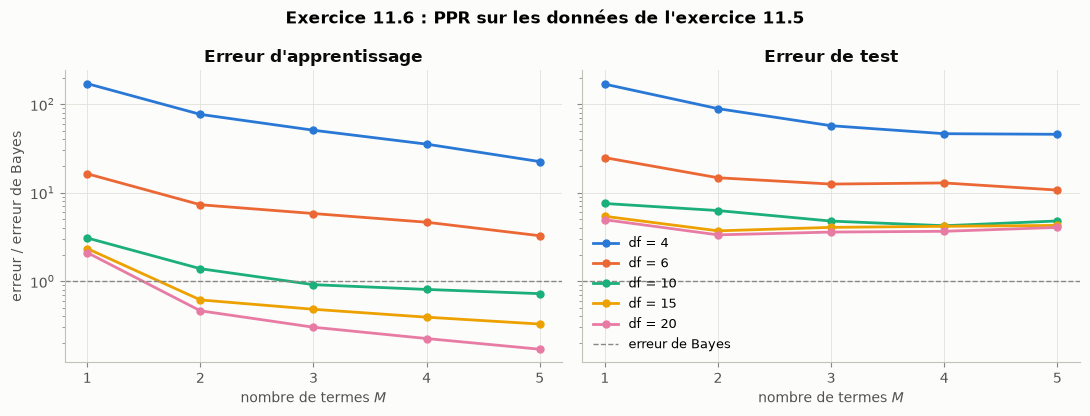

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for c, (i, df) in zip(COLORS, enumerate(dfs)):
    axes[0].plot(M_ppr, err_ppr_app[i], "o-", color=c, label="df = %d" % df)
    axes[1].plot(M_ppr, err_ppr[i], "o-", color=c, label="df = %d" % df)
for ax, t in zip(axes, ["apprentissage", "test"]):
    ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
    ax.set_yscale("log")
    ax.set_xticks(M_ppr)
    ax.set_xlabel("nombre de termes $M$")
    ax.set_title("Erreur d'%s" % t if t == "apprentissage" else "Erreur de %s" % t)
axes[0].set_ylabel("erreur / erreur de Bayes")
axes[1].legend()
fig.suptitle("Exercice 11.6 : PPR sur les données de l'exercice 11.5", fontweight="bold")
plt.tight_layout()
plt.show()

Observations :

* avec **peu** de degrés de liberté ($\mathrm{df} = 4$), chaque spline est trop lissée (trop rigide) pour
  reproduire la parabole et ses grandes valeurs : il faut empiler de nombreux termes ;
* avec $\mathrm{df} \ge 10$, **un seul** terme dans la direction $a_2$ capture déjà la parabole
  (l'erreur chute de plusieurs ordres de grandeur par rapport à la constante, dont l'erreur
  relative est de l'ordre de $\mathrm{Var}\,Y/0{,}09 \approx 7000$), et **deux** termes suffisent à
  ajouter la sigmoïde dans la direction $a_1$ ; au-delà, l'erreur de test ne diminue plus
  guère.

Vérifions les directions trouvées avec $\mathrm{df} = 15$ et $M = 2$, et traçons les deux fonctions
ridge.

In [15]:
ppr2 = PPR(n_terms=2, df=15, random_state=0).fit(X, y)
for m, w in enumerate(ppr2.omegas_):
    print("terme %d : omega = %s, |cos(omega, a1)| = %.3f, |cos(omega, a2)| = %.3f"
          % (m + 1, np.round(w, 3), abs(w @ a1) / np.linalg.norm(a1), abs(w @ a2) / np.linalg.norm(a2)))

terme 1 : omega = [ 0.708 -0.706], |cos(omega, a1)| = 0.001, |cos(omega, a2)| = 1.000
terme 2 : omega = [0.697 0.717], |cos(omega, a1)| = 1.000, |cos(omega, a2)| = 0.014


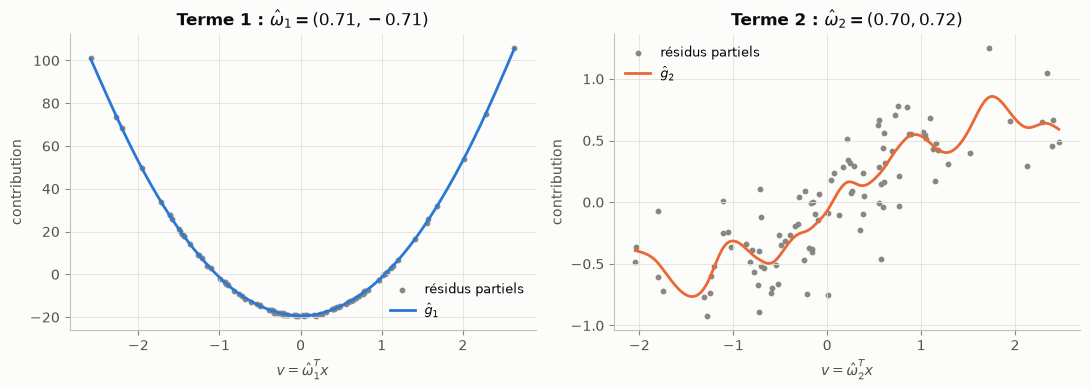

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
contrib = ppr2.ridge_functions(X)
for m, ax in enumerate(axes):
    w = ppr2.omegas_[m]
    v = X @ w
    vv = np.linspace(v.min(), v.max(), 200)
    partiel = y - ppr2.mean_ - (contrib.sum(axis=1) - contrib[:, m])
    ax.scatter(v, partiel, s=10, color=GRAY, label="résidus partiels")
    ax.plot(vv, ppr2.smoothers_[m].predict(vv), color=COLORS[m], label=r"$\hat g_%d$" % (m + 1))
    ax.set_xlabel(r"$v = \hat\omega_%d^Tx$" % (m + 1))
    ax.set_ylabel("contribution")
    ax.set_title(r"Terme %d : $\hat\omega_%d = (%.2f, %.2f)$" % (m + 1, m + 1, *w))
    ax.legend()
plt.tight_layout()
plt.show()

La PPR retrouve la structure exacte du modèle : une parabole dans la direction
$a_2/\|a_2\| = (1, -1)/\sqrt2$ et une sigmoïde dans la direction $a_1/\|a_1\| = (1, 1)/\sqrt2$. La
seconde fonction, avec 15 degrés de liberté, est cependant trop ondulée : ses résidus partiels
contiennent, en plus du bruit, les erreurs d'ajustement de la parabole, beaucoup plus grandes
que la sigmoïde elle-même. C'est le sur-ajustement typique d'un lisseur trop souple.

**Comparaison avec le réseau.** La PPR a besoin de **2** termes (un par fonction ridge du vrai
modèle), car ses fonctions $g_m$ sont non paramétriques et peuvent prendre n'importe quelle forme
- en particulier celle d'une parabole. Le réseau, dont chaque terme est une sigmoïde monotone,
a besoin de **2 unités** pour obtenir une bonne approximation de la seule parabole, et d'une
**troisième** pour la sigmoïde. Chaque terme de PPR est plus « coûteux » (un lissage non
paramétrique à df degrés de liberté) mais plus expressif qu'une unité cachée.

En **précision**, en revanche, le réseau à 2 ou 3 unités fait mieux ici (environ 1,4 fois l'erreur
de Bayes, contre 3 à 4 fois pour la meilleure PPR). La pénalité de rugosité $\lambda\int g''^2$ de
la spline pénalise justement la courbure de la parabole (dont la dérivée seconde vaut
$2\|a_2\|^2 = 36$ partout) : elle introduit un **biais** de lissage, surtout dans les queues où les
données sont rares et où la parabole prend de très grandes valeurs.

> **À retenir.** Avec des splines suffisamment souples (df ≳ 10), la PPR retrouve les deux directions
> du modèle et deux termes suffisent, contre deux à trois unités cachées pour le réseau. Des
> splines trop rigides obligent à multiplier les termes.

## Exercice 11.7 : Réseau de neurones et modèle additif sur les données *spam*

**Énoncé (reformulé).** Ajuster un réseau de neurones aux données *spam* de la section 9.1.2 et
comparer les résultats à ceux du modèle additif présenté dans ce chapitre : performance de
classification et interprétabilité du modèle final.

### Les données et le protocole

Les données comportent 4601 courriels décrits par 57 variables (fréquences de 48 mots et de 6
caractères, et trois mesures des suites de majuscules) ; la réponse vaut 1 pour un spam. Comme à
la section 9.1.2, on transforme chaque variable par $x \mapsto \log(x + 0{,}1)$ (les variables sont
très asymétriques, avec beaucoup de zéros), puis on standardise. On sépare aléatoirement 3065
courriels d'apprentissage et 1536 de test, comme dans le livre (qui obtient une erreur de test de
**5,3 %** avec le modèle additif).

In [17]:
noms = ["make", "address", "all", "3d", "our", "over", "remove", "internet", "order", "mail",
        "receive", "will", "people", "report", "addresses", "free", "business", "email", "you",
        "credit", "your", "font", "000", "money", "hp", "hpl", "george", "650", "lab", "labs",
        "telnet", "857", "data", "415", "85", "technology", "1999", "parts", "pm", "direct", "cs",
        "meeting", "original", "project", "re", "edu", "table", "conference", "ch;", "ch(", "ch[",
        "ch!", "ch$", "ch#", "CAPAVE", "CAPMAX", "CAPTOT"]
spam = datasets.load_spam()
X_brut = spam.drop(columns="spam").to_numpy(float)
y_sp = spam["spam"].to_numpy()
rng = np.random.RandomState(0)
perm = rng.permutation(len(y_sp))
i_test, i_app = perm[:1536], perm[1536:]
L = np.log(X_brut + 0.1)
moy, et = L[i_app].mean(axis=0), L[i_app].std(axis=0)
Z_sp = (L - moy) / et
print("apprentissage :", len(i_app), " test :", len(i_test), " proportion de spam :", y_sp.mean().round(3))

apprentissage : 3065  test : 1536  proportion de spam : 0.394


Pour choisir les paramètres de régularisation, on réserve 765 courriels de l'ensemble
d'apprentissage comme ensemble de **validation** ; une fois les paramètres choisis, on réajuste
sur les 3065 courriels d'apprentissage.

In [18]:
i_val, i_fit = i_app[:765], i_app[765:]

def taux_erreur(prob1, idx):
    return np.mean((prob1 > 0.5) != y_sp[idx])

### Le modèle additif

Le modèle additif logistique du chapitre 9 s'écrit
$\mathrm{logit}\,P(Y = 1\mid x) = \beta_0 + \sum_{j=1}^{57} f_j(x_j)$, chaque $f_j$ étant une fonction lisse
d'**une seule** variable. Le livre l'ajuste par *backfitting* avec des splines de lissage à
4 degrés de liberté. Nous en ajustons une version proche, les **P-splines** (splines pénalisées) :

* chaque $f_j$ est une spline cubique, combinaison de $q = 9$ **B-splines** à nœuds équirépartis
  sur l'étendue de $x_j$ : $f_j(x_j) = \sum_{r=1}^q b_{jr}\,B_{r}^{(j)}(x_j)$ ;
* la régularité est imposée par une pénalité sur les **différences secondes** des coefficients,
  $\lambda\sum_j\sum_r (b_{j,r+2} - 2b_{j,r+1} + b_{jr})^2 = \lambda\, b^T P\, b$, analogue discret de
  $\lambda\int f_j''^2$ : quand $\lambda\to\infty$, chaque $f_j$ devient (presque) linéaire ;
* on maximise la log-vraisemblance pénalisée par l'algorithme de **Newton–Raphson** (moindres
  carrés repondérés itérés, chapitre 4) : pour $\ell(b) = \sum_i [y_i\eta_i - \log(1+e^{\eta_i})]$, le
  gradient du critère $-\ell(b) + b^TPb$ est $A^T(p - y) + 2Pb$ et sa hessienne $A^TWA + 2P$, où $A$ est
  la matrice de base (avec une colonne de 1), $p_i = \sigma(\eta_i)$ et $W = \mathrm{diag}(p_i(1-p_i))$.

(Une petite pénalité ridge $10^{-6}\|b\|^2$ lève l'indétermination entre la constante $\beta_0$ et
les constantes des $f_j$.)

In [19]:
from scipy.interpolate import BSpline

bornes = [(Z_sp[i_app, j].min(), Z_sp[i_app, j].max()) for j in range(Z_sp.shape[1])]

def base_additive(Z, n_int=5, k=3):
    """Matrice des B-splines cubiques de chaque variable (nœuds équirépartis)."""
    blocs = []
    for j in range(Z.shape[1]):
        lo, hi = bornes[j]
        t = np.r_[[lo] * (k + 1), np.linspace(lo, hi, n_int + 2)[1:-1], [hi] * (k + 1)]
        blocs.append(BSpline.design_matrix(np.clip(Z[:, j], lo, hi), t, k).toarray())
    return np.hstack(blocs)

B_sp = base_additive(Z_sp)
q = B_sp.shape[1] // Z_sp.shape[1]
D2 = np.diff(np.eye(q), 2, axis=0)                  # différences secondes (q-2, q)
P_bloc = np.kron(np.eye(Z_sp.shape[1]), D2.T @ D2)  # pénalité bloc-diagonale
print("matrice de base :", B_sp.shape, "; B-splines par variable :", q)

matrice de base : (4601, 513) ; B-splines par variable : 9


In [20]:
class ModeleAdditif:
    """Modèle additif logistique par P-splines, ajusté par Newton–Raphson."""

    def __init__(self, lam):
        self.lam = lam

    def fit(self, B, y, n_iter=50):
        A = np.column_stack([np.ones(len(y)), B])
        n = A.shape[1]
        pen = np.zeros((n, n))
        pen[1:, 1:] = self.lam * P_bloc + 1e-6 * np.eye(n - 1)
        b = np.zeros(n)
        for _ in range(n_iter):
            p = sigmoid(A @ b)
            grad = A.T @ (p - y) + 2 * pen @ b
            hess = (A * (p * (1 - p))[:, None]).T @ A + 2 * pen
            pas = np.linalg.solve(hess, grad)
            b -= pas
            if np.max(np.abs(pas)) < 1e-8:
                break
        self.coef_ = b
        return self

    def proba(self, B):
        return sigmoid(self.coef_[0] + B @ self.coef_[1:])

def ajuster_additif(idx, lam):
    return ModeleAdditif(lam).fit(B_sp[idx], y_sp[idx])

grille_add = [0.1, 1.0, 10.0, 100.0]
for lam in grille_add:
    m = ajuster_additif(i_fit, lam)
    print("additif, lambda = %6.1f : erreur de validation = %.3f"
          % (lam, taux_erreur(m.proba(B_sp[i_val]), i_val)))

additif, lambda =    0.1 : erreur de validation = 0.055


additif, lambda =    1.0 : erreur de validation = 0.055


additif, lambda =   10.0 : erreur de validation = 0.060


additif, lambda =  100.0 : erreur de validation = 0.065


### Le réseau de neurones

Réseau à $M = 10$ unités cachées sur les 57 variables transformées, sortie softmax, entropie
croisée, weight decay $\lambda$ choisi par validation. Pour limiter la dépendance aux poids
initiaux, on **moyenne les probabilités** de 3 réseaux ajustés depuis des départs différents
(section 11.5.5).

In [21]:
def ajuster_reseau(idx, lam, M=10, n_starts=3):
    return [MLP(n_hidden=M, output="softmax", loss="cross_entropy", weight_decay=lam,
                random_state=s).fit(Z_sp[idx], one_hot(y_sp[idx], 2), max_iter=1000)
            for s in range(n_starts)]

def proba_reseaux(nets, Z):
    return np.mean([n.predict(Z)[:, 1] for n in nets], axis=0)

for lam in [0.3, 1.0, 3.0, 10.0]:
    nets = ajuster_reseau(i_fit, lam)
    print("réseau, lambda = %5.1f : erreur de validation = %.3f"
          % (lam, taux_erreur(proba_reseaux(nets, Z_sp[i_val]), i_val)))

réseau, lambda =   0.3 : erreur de validation = 0.050


réseau, lambda =   1.0 : erreur de validation = 0.058


réseau, lambda =   3.0 : erreur de validation = 0.059
réseau, lambda =  10.0 : erreur de validation = 0.065


### Comparaison des performances

On retient pour chaque méthode la valeur de $\lambda$ de plus faible erreur de validation, on
réajuste sur tout l'ensemble d'apprentissage et l'on évalue sur l'ensemble de test. On ajoute
la régression logistique **linéaire** (réseau sans couche cachée sur les 57 variables) comme
référence.

In [22]:
def choisir(ajuster, proba, grille):
    errs = [taux_erreur(proba(ajuster(i_fit, l), i_val), i_val) for l in grille]
    return grille[int(np.argmin(errs))]

lam_add = choisir(ajuster_additif, lambda m, idx: m.proba(B_sp[idx]), grille_add)
lam_nn = choisir(ajuster_reseau, lambda n, idx: proba_reseaux(n, Z_sp[idx]), [0.3, 1.0, 3.0, 10.0])
additif = ajuster_additif(i_app, lam_add)
reseau = ajuster_reseau(i_app, lam_nn)
lineaire = MLP(n_hidden=0, output="softmax", loss="cross_entropy", weight_decay=1.0).fit(
    Z_sp[i_app], one_hot(y_sp[i_app], 2), max_iter=2000)

p_add = additif.proba(B_sp[i_test])
p_nn = proba_reseaux(reseau, Z_sp[i_test])
p_lin = lineaire.predict(Z_sp[i_test])[:, 1]
for nom, pr, lam in [("logistique linéaire", p_lin, 1.0), ("modèle additif", p_add, lam_add),
                     ("réseau (M = 10)", p_nn, lam_nn)]:
    e = taux_erreur(pr, i_test)
    print("%-20s (lambda = %4.1f) : erreur de test = %.3f  (écart-type ≈ %.3f)"
          % (nom, lam, e, np.sqrt(e * (1 - e) / len(i_test))))

logistique linéaire  (lambda =  1.0) : erreur de test = 0.057  (écart-type ≈ 0.006)
modèle additif       (lambda =  0.1) : erreur de test = 0.055  (écart-type ≈ 0.006)
réseau (M = 10)      (lambda =  0.3) : erreur de test = 0.050  (écart-type ≈ 0.006)


Les trois modèles obtiennent des erreurs de test proches : de l'ordre de 5 % pour le réseau,
5,5 % pour le modèle additif (le livre obtient 5,3 %) et un peu plus pour le modèle linéaire.
L'écart-type binomial de ces estimations, $\sqrt{e(1-e)/1536} \approx 0{,}6\,\%$, est du même ordre
que les écarts entre méthodes : on ne peut pas conclure à une supériorité nette.

Le livre donne aussi la **matrice de confusion** (tableau 9.1) ; comparons-les, en se rappelant que
classer un vrai courriel en spam est l'erreur la plus grave.

In [23]:
for nom, pr in [("modèle additif", p_add), ("réseau", p_nn)]:
    pred = (pr > 0.5).astype(int)
    vrai = y_sp[i_test]
    tab = np.array([[np.mean((vrai == a) & (pred == b)) for b in (0, 1)] for a in (0, 1)]) * 100
    print("%s (en %% des courriels de test ; lignes : vraie classe courriel/spam, colonnes : prédite)" % nom)
    print(np.round(tab, 1))

modèle additif (en % des courriels de test ; lignes : vraie classe courriel/spam, colonnes : prédite)
[[57.3  2.2]
 [ 3.3 37.2]]
réseau (en % des courriels de test ; lignes : vraie classe courriel/spam, colonnes : prédite)
[[57.2  2.3]
 [ 2.7 37.8]]


### Interprétabilité

**Modèle additif.** Chaque variable a sa propre fonction $\hat f_j$, que l'on peut tracer : c'est
l'effet de $x_j$ sur le logit **toutes choses égales par ailleurs**, et il ne dépend pas des
autres variables. Le modèle se lit comme un modèle linéaire généralisé.

**Réseau.** Chaque variable intervient dans les dix unités cachées, à travers des sigmoïdes, et
son effet dépend des valeurs des autres variables (interactions). On ne peut qu'en donner des
résumés, par exemple la **dépendance partielle** : pour une variable $j$ et une valeur $v$, on
remplace $x_j$ par $v$ dans tous les courriels et l'on moyenne le logit prédit,

$$\bar f_j(v) = \frac1N\sum_{i=1}^N \mathrm{logit}\,\hat P\big(Y = 1 \mid x_{i, -j},\ x_{ij} = v\big).$$

Pour un modèle additif, cette dépendance partielle redonne exactement $\hat f_j$ (à une constante
près) : nous l'utilisons donc pour les deux modèles.

In [24]:
def logit(p):
    p = np.clip(p, 1e-10, 1 - 1e-10)
    return np.log(p / (1 - p))

def dependance_partielle(predire, j, valeurs, idx):
    Zb = Z_sp[idx].copy()
    out = []
    for v in valeurs:
        Zb[:, j] = v
        out.append(np.mean(logit(predire(Zb))))
    return np.array(out)

predire_add = lambda Z: additif.proba(base_additive(Z))
predire_nn = lambda Z: proba_reseaux(reseau, Z)

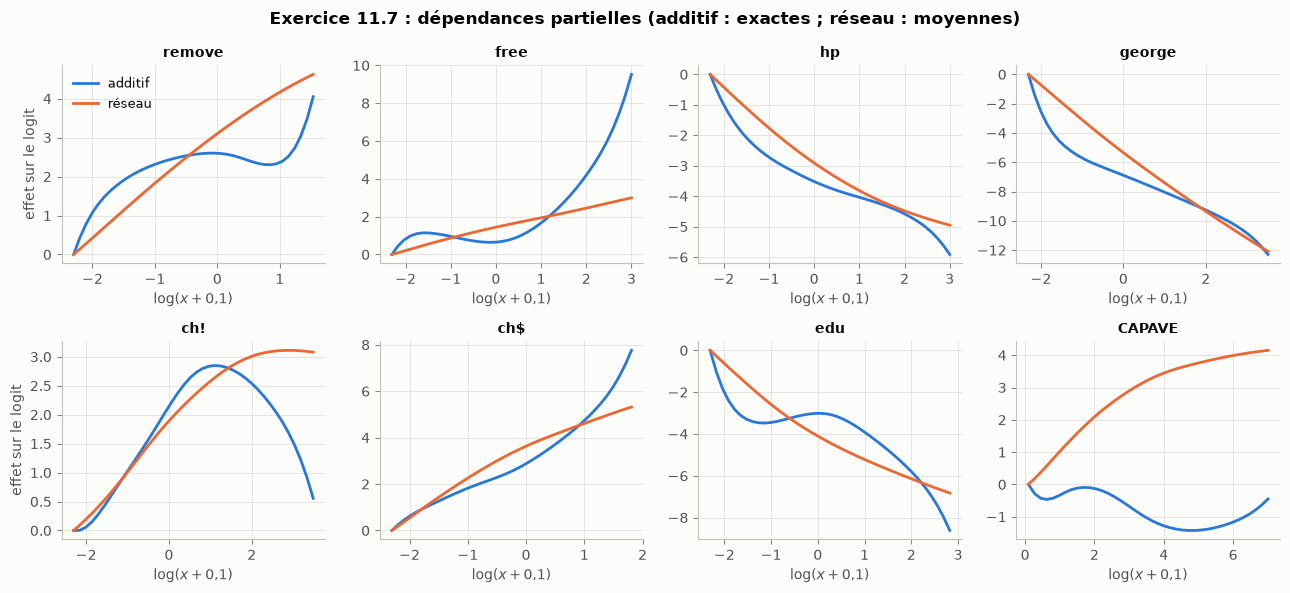

In [25]:
choix = ["remove", "free", "hp", "george", "ch!", "ch$", "edu", "CAPAVE"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
idx_pd = i_test[:400]
for ax, nom in zip(axes.ravel(), choix):
    j = noms.index(nom)
    zz = np.linspace(bornes[j][0], bornes[j][1], 40)
    xx = np.exp(zz * et[j] + moy[j]) - 0.1          # retour à l'échelle d'origine
    for c, (lab, f) in zip([BLUE, ORANGE], [("additif", predire_add), ("réseau", predire_nn)]):
        pdv = dependance_partielle(f, j, zz, idx_pd)
        ax.plot(np.log(xx + 0.1), pdv - pdv[0], color=c, label=lab)
    ax.set_title(nom, fontsize=10)
    ax.set_xlabel(r"$\log(x + 0{,}1)$")
axes[0, 0].set_ylabel("effet sur le logit")
axes[1, 0].set_ylabel("effet sur le logit")
axes[0, 0].legend()
fig.suptitle("Exercice 11.7 : dépendances partielles (additif : exactes ; réseau : moyennes)",
             fontweight="bold")
plt.tight_layout()
plt.show()

Les effets estimés vont dans le même sens pour les deux modèles : les mots « remove », « free »
et les caractères « ! » et « $ » augmentent la probabilité de spam, alors que « hp », « george »
(le destinataire travaillait chez HP et s'appelait George) et « edu » la diminuent. Les courbes
du réseau sont plus régulières (sigmoïdes) mais elles ne sont que des **moyennes** : pour un
courriel donné, l'effet d'une variable dépend des autres. Les désaccords les plus nets
concernent des variables très **corrélées** entre elles (comme CAPAVE, CAPMAX et CAPTOT, trois
mesures des suites de majuscules) : les deux modèles peuvent répartir différemment un même
effet entre ces variables, ce qui illustre la fragilité de l'interprétation variable par
variable.

Mesurons l'**importance** de chaque variable par permutation : on permute aléatoirement la
colonne $j$ des données de test (ce qui casse son lien avec la réponse) et l'on mesure
l'augmentation de l'erreur de test.

In [26]:
def importance_permutation(predire, idx, rng):
    base = taux_erreur(predire(Z_sp[idx]), idx)
    imp = np.zeros(Z_sp.shape[1])
    for j in range(Z_sp.shape[1]):
        Zp = Z_sp[idx].copy()
        Zp[:, j] = rng.permutation(Zp[:, j])
        imp[j] = taux_erreur(predire(Zp), idx) - base
    return imp

rng = np.random.RandomState(0)
imp_add = importance_permutation(predire_add, i_test, rng)
imp_nn = importance_permutation(predire_nn, i_test, rng)

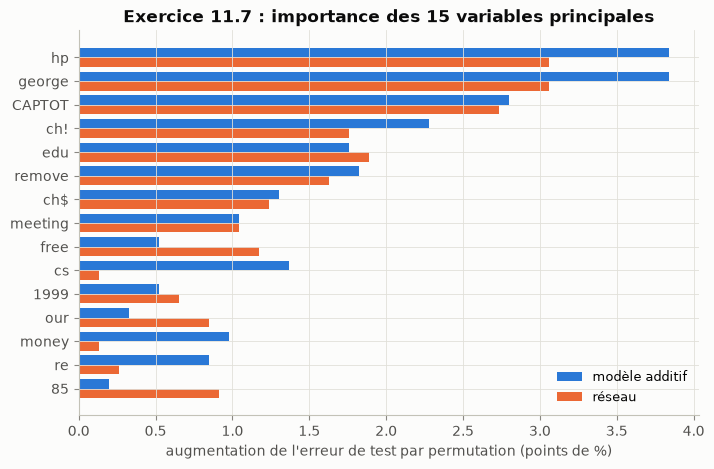

In [27]:
ordre = np.argsort(imp_add + imp_nn)[::-1][:15]
fig, ax = plt.subplots(figsize=(8, 5))
pos = np.arange(len(ordre))
ax.barh(pos - 0.2, 100 * imp_add[ordre], height=0.4, color=BLUE, label="modèle additif")
ax.barh(pos + 0.2, 100 * imp_nn[ordre], height=0.4, color=ORANGE, label="réseau")
ax.set_yticks(pos, [noms[j] for j in ordre])
ax.invert_yaxis()
ax.set_xlabel("augmentation de l'erreur de test par permutation (points de %)")
ax.set_title("Exercice 11.7 : importance des 15 variables principales")
ax.legend()
plt.show()

In [28]:
corr = np.corrcoef(imp_add, imp_nn)[0, 1]
print("corrélation entre les importances des deux modèles : %.2f" % corr)

corrélation entre les importances des deux modèles : 0.90


**Bilan de la comparaison.**

* **Performance** : réseau et modèle additif ont des erreurs de test proches (5 à 5,5 %), à peine
  meilleures que le modèle linéaire ; les interactions que le réseau peut capter n'apportent
  pas de gain significatif sur ces données. Les matrices de confusion sont semblables.
* **Interprétabilité** : le modèle additif est nettement plus lisible. Ses 57 fonctions $\hat f_j$
  décrivent exactement le modèle, chacune se lit isolément et l'on peut en tester la
  linéarité. Le réseau ($10 \times 58 + 2 \times 11 = 602$ poids) ne se laisse décrire que par des résumés
  (dépendances partielles, importances) qui ne caractérisent pas complètement le modèle ; ses
  poids individuels ne sont pas identifiables.
* Les deux modèles s'accordent sur les variables importantes (« ! », « $ », « remove », « hp »,
  « free »…), ce qui renforce la confiance dans ces conclusions.

> **À retenir.** À performance égale, le modèle additif est préférable dès que l'on veut
> comprendre et expliquer le classifieur ; le réseau est un outil de prédiction « boîte noire »
> qu'il faut résumer a posteriori.